## AI101 Mini-Project Group 50

Predicting Employee Attrition Based on Workplace and Personal Factors Using Logistic Regression

Section 1 - Dataset understanding

### 1.1 Import Libraries

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1.2 Read Dataset

In [43]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")


#### 1.3 Display Shape of DataSet


In [44]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1470, 35)


#### 1.4 Display first Five rows


In [45]:
print("First Five Rows:\n") 
df.head(5)

First Five Rows:



,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


#### 1.5 Dataset Information


In [46]:
print("Column Names :\n",df.columns.tolist())
print("Dataset Information:\n")
df.info()

Column Names :
 ['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Dataset Information:

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470

#### 1.6 Missing Values

In [47]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percent
}).sort_values("Missing Values", ascending=False)

display(missing_summary)

,Missing Values,Missing Percentage
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0


#### 1.7 Statistics Summary

In [48]:
print("\nSummary of numeric columns:")
display(df.describe())


Summary of numeric columns:


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


#### 1.8 Numeric and Categorical columns

In [49]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric columns:", len(numeric_columns))
print(numeric_columns)
print("\nCategorical columns:", len(categorical_columns))
print(categorical_columns)

print("\nNumerical summary:")
display(df[numeric_columns].describe().T)

print("\nCategorical summary:")
display(df[categorical_columns].describe().T)

Numeric columns: 26
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical columns: 9
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0



Categorical summary:


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


#### 1.9 Duplicate Rows

In [50]:
duplicate_rows_count = df.duplicated().sum()
print("Number of completely duplicated rows:", duplicate_rows_count)

Number of completely duplicated rows: 0


#### 1.10 Target Variable Inspection


Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


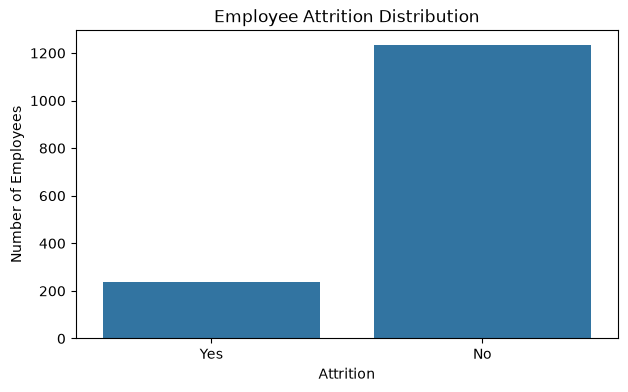

In [51]:
TARGET = "Attrition"
data = df.copy()
if TARGET not in data.columns:
    raise KeyError("Attrition column not found!")

print("Attrition Count:")
print(data[TARGET].value_counts())
print("\nAttrition Percentage:")
print((data[TARGET].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 4))
sns.countplot(x=TARGET, data=data)
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

SECTION-2 DATA PREPROCESSING

2.1 Making copy and removing unnecessary columns

In [52]:
data = df.copy()
data = data.drop(
    ["EmployeeNumber", "EmployeeCount", "Over18", "StandardHours"],
    axis=1
)
print("Shape after removing columns:", data.shape)

Shape after removing columns: (1470, 31)


2.2 Check missing values and duplicates 

In [53]:
data = data.drop_duplicates()
for col in data.columns:
    if data[col].isnull().sum() > 0:
        if data[col].dtype == "object":
            data[col] = data[col].fillna(data[col].mode()[0])
        else:
            data[col] = data[col].fillna(data[col].median())
print("Missing values after cleaning:", data.isnull().sum().sum())
print("Shape after cleaning:", data.shape)

Missing values after cleaning: 0
Shape after cleaning: (1470, 31)


2.3 Convert categorical columns into numbers

In [54]:
data["Attrition"] = data["Attrition"].map({"No": 0, "Yes": 1})
data = pd.get_dummies(data, drop_first=True)

display(data.head())
print("New number of columns:", data.shape[1])

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1,1102,1,2,2,94,3,2,4,...,False,False,False,False,False,True,False,False,True,True
1,49,0,279,8,1,3,61,2,2,2,...,False,False,False,False,True,False,False,True,False,False
2,37,1,1373,2,2,4,92,2,1,3,...,True,False,False,False,False,False,False,False,True,True
3,33,0,1392,3,4,4,56,3,1,3,...,False,False,False,False,True,False,False,True,False,True
4,27,0,591,2,1,1,40,3,1,2,...,True,False,False,False,False,False,False,True,False,False


New number of columns: 45


2.4 Checking highly correlated features

In [55]:
# Select useful numerical columns for correlation checking
corr_features = [
    "Age", "DailyRate", "DistanceFromHome", "Education",
    "EnvironmentSatisfaction", "HourlyRate", "JobInvolvement",
    "JobLevel", "JobSatisfaction", "MonthlyIncome", "MonthlyRate",
    "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating",
    "RelationshipSatisfaction", "StockOptionLevel", "TotalWorkingYears",
    "TrainingTimesLastYear", "WorkLifeBalance", "YearsAtCompany",
    "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"
]

# Calculate correlation matrix
corr_matrix = df[corr_features].corr()

# Identify strongly correlated pairs
strong_corr = corr_matrix.where(
    corr_matrix.abs() > 0.7
).stack().reset_index()

strong_corr.columns = [
    "Feature 1", "Feature 2", "Correlation"
]

# Remove duplicate pairs and self-correlations
strong_corr = strong_corr[
    (strong_corr["Feature 1"] < strong_corr["Feature 2"])
]

print("Strongly correlated feature pairs (absolute correlation > 0.7):")
if strong_corr.empty:
    print("No strongly correlated pairs were found.")
else:
    print(strong_corr.to_string(index=False))

Strongly correlated feature pairs (absolute correlation > 0.7):
               Feature 1                Feature 2  Correlation
                     Age                DailyRate          NaN
                     Age         DistanceFromHome          NaN
                     Age                Education          NaN
                     Age  EnvironmentSatisfaction          NaN
                     Age               HourlyRate          NaN
                     Age           JobInvolvement          NaN
                     Age                 JobLevel          NaN
                     Age          JobSatisfaction          NaN
                     Age            MonthlyIncome          NaN
                     Age              MonthlyRate          NaN
                     Age       NumCompaniesWorked          NaN
                     Age        PercentSalaryHike          NaN
                     Age        PerformanceRating          NaN
                     Age RelationshipSatisfaction     

2.5 Removing one highly correlated feature

YearsInCurrentRole  is removed because it overlaps strongly with YearsAtCompany and YearsWithCurrManager; checking possible single-feature removals with cross-validation on the training data showing that removing this feature gave the highest mean accuracy

In [56]:
data = data.drop("YearsInCurrentRole", axis=1)

print("Removed feature: YearsInCurrentRole")
print("Number of features after removal:", data.drop("Attrition", axis=1).shape[1])

Removed feature: YearsInCurrentRole
Number of features after removal: 43


2.6 Separate input features and target

In [57]:
X = data.drop("Attrition", axis=1)
y = data["Attrition"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1470, 43)
Target shape: (1470,)


2.7 Split data

In [58]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 1176
Testing rows: 294


2.8 Feature scaling

In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Section-3 Model Training

### 3.1 Import required libraries

In [60]:
from sklearn.linear_model import LogisticRegression
print("Libraries imported Successfully")

Libraries imported Successfully


### 3.2 Training model

In [61]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 3.3 Learning Curve and Loss Curve


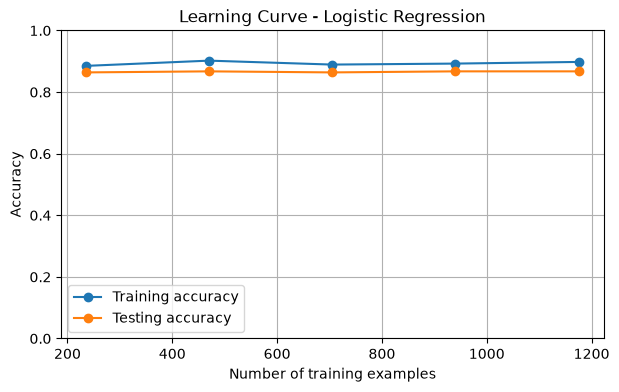

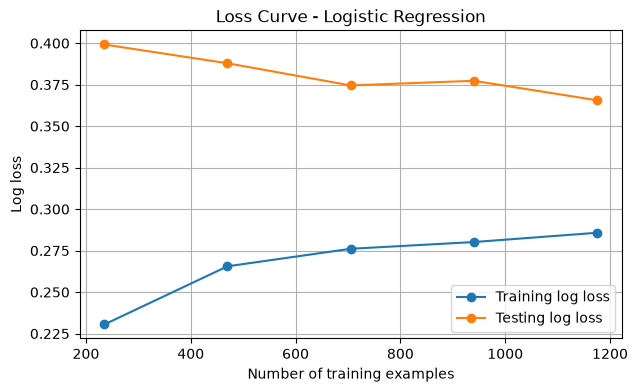

,Training examples,Training accuracy,Testing accuracy,Training log loss,Testing log loss
0,235,0.8851,0.8639,0.2305,0.3992
1,470,0.9021,0.8673,0.2655,0.3879
2,705,0.8894,0.8639,0.2761,0.3745
3,940,0.8926,0.8673,0.2802,0.3773
4,1176,0.8980,0.8673,0.2858,0.3656


In [62]:
from sklearn.metrics import log_loss, accuracy_score
from sklearn.model_selection import train_test_split

# Try different sizes of the training data
train_sizes = [0.2, 0.4, 0.6, 0.8, 1.0]
train_accuracies = []
test_accuracies = []
train_losses = []
test_losses = []

for size in train_sizes:
    # Select a smaller part of the training data
    if size < 1.0:
        X_small, _, y_small, _ = train_test_split(
            X_train_scaled, y_train,
            train_size=size,
            random_state=42,
            stratify=y_train
        )
    else:
        X_small = X_train_scaled
        y_small = y_train

    # Train a new Logistic Regression model on this part
    temp_model = LogisticRegression(max_iter=1000)
    temp_model.fit(X_small, y_small)

    # Calculate accuracy for training and testing data
    train_pred = temp_model.predict(X_small)
    test_pred = temp_model.predict(X_test_scaled)
    train_accuracies.append(accuracy_score(y_small, train_pred))
    test_accuracies.append(accuracy_score(y_test, test_pred))

    # Calculate log loss for training and testing data
    train_prob = temp_model.predict_proba(X_small)
    test_prob = temp_model.predict_proba(X_test_scaled)
    train_losses.append(log_loss(y_small, train_prob, labels=[0, 1]))
    test_losses.append(log_loss(y_test, test_prob, labels=[0, 1]))

# Convert training sizes into number of rows
number_of_rows = [int(size * len(X_train)) for size in train_sizes]

# Plot the learning curve
plt.figure(figsize=(7, 4))
plt.plot(number_of_rows, train_accuracies, marker="o", label="Training accuracy")
plt.plot(number_of_rows, test_accuracies, marker="o", label="Testing accuracy")
plt.title("Learning Curve - Logistic Regression")
plt.xlabel("Number of training examples")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.show()

# Plot the loss curve
plt.figure(figsize=(7, 4))
plt.plot(number_of_rows, train_losses, marker="o", label="Training log loss")
plt.plot(number_of_rows, test_losses, marker="o", label="Testing log loss")
plt.title("Loss Curve - Logistic Regression")
plt.xlabel("Number of training examples")
plt.ylabel("Log loss")
plt.legend()
plt.grid()
plt.show()

# Display the values used in both curves
curve_results = pd.DataFrame({
    "Training examples": number_of_rows,
    "Training accuracy": train_accuracies,
    "Testing accuracy": test_accuracies,
    "Training log loss": train_losses,
    "Testing log loss": test_losses
})

display(curve_results.round(4))

### 3.4 Make Predictions

In [63]:
from sklearn.metrics import accuracy_score
lr_pred = lr_model.predict(X_test_scaled)
print("First 10 predictions:", lr_pred[:10])
print("First 10 actual values:", y_test.iloc[:10].to_list())

First 10 predictions: [0 0 0 0 0 0 0 0 0 0]
First 10 actual values: [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]


### 3.5 Predict one unseen employee

In [64]:
sample = X_test_scaled[0].reshape(1, -1)

sample_prediction = lr_model.predict(sample)[0]
actual_value = y_test.iloc[0]

print("Predicted class:", sample_prediction)
print("Actual class:", actual_value)

if sample_prediction == 1:
    print("Model prediction: Employee may leave.")
else:
    print("Model prediction: Employee may stay.")

print("Prediction correct:", sample_prediction == actual_value)

Predicted class: 0
Actual class: 0
Model prediction: Employee may stay.
Prediction correct: True


## Section-4 Model Analysis

In [65]:
lr_accuracy = accuracy_score(y_test, lr_pred)
print("Accuracy:", round(lr_accuracy, 4))
print("Accuracy percentage:", round(lr_accuracy * 100, 2), "%")

Accuracy: 0.8673
Accuracy percentage: 86.73 %


### 4.2 Confusion matrix

[[238   9]
 [ 30  17]]


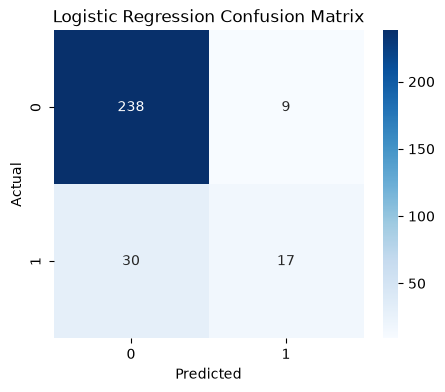

In [66]:
from sklearn.metrics import confusion_matrix

lr_cm = confusion_matrix(y_test, lr_pred)
print(lr_cm)

plt.figure(figsize=(5, 4))
sns.heatmap(lr_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 4.3 Precision, recall and F1-score

In [67]:
from sklearn.metrics import precision_score, recall_score, f1_score
lr_precision = precision_score(y_test, lr_pred, zero_division=0)
lr_recall = recall_score(y_test, lr_pred, zero_division=0)
lr_f1 = f1_score(y_test, lr_pred, zero_division=0)
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1-score:", round(lr_f1, 4))

Precision: 0.6538
Recall: 0.3617
F1-score: 0.4658


### 4.4 Classification report

In [68]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    lr_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

              precision    recall  f1-score   support

      Stayed       0.89      0.96      0.92       247
        Left       0.65      0.36      0.47        47

    accuracy                           0.87       294
   macro avg       0.77      0.66      0.70       294
weighted avg       0.85      0.87      0.85       294



### 4.5 ROC Curve and ROC-AUC Score

ROC-AUC Score: 0.7985


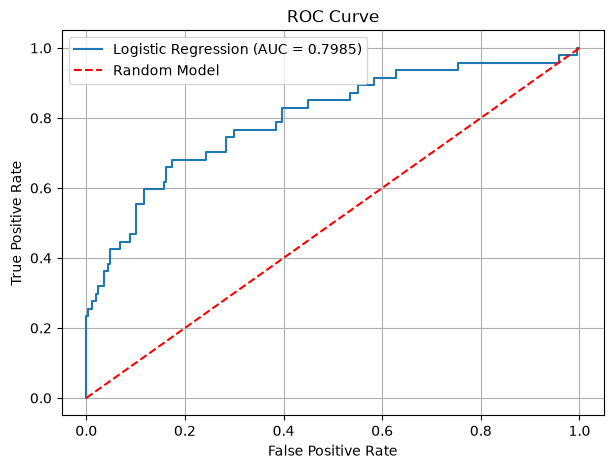

In [69]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get prediction probabilities
y_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(roc_auc, 4))

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="Logistic Regression (AUC = {:.4f})".format(roc_auc))
plt.plot([0, 1], [0, 1], linestyle="--", color="red", label="Random Model")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

### 4.6 Precision-Recall Curve

Precision-Recall AUC Score: 0.5735


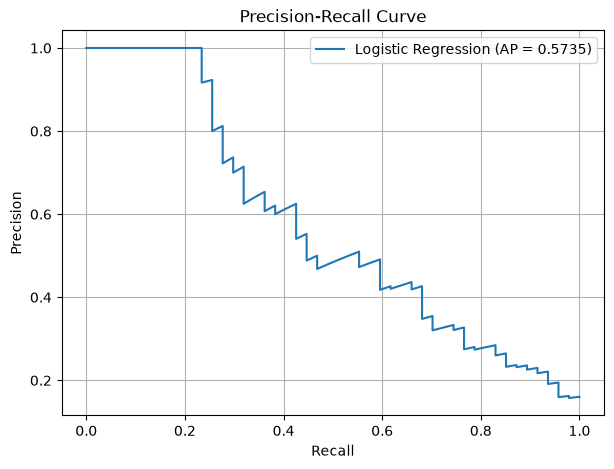

In [70]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision and recall values
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

# Calculate average precision score
pr_score = average_precision_score(y_test, y_prob)

print("Precision-Recall AUC Score:", round(pr_score, 4))

# Plot Precision-Recall curve
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label="Logistic Regression (AP = {:.4f})".format(pr_score))

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()